In [ ]:
# Кейс 3. Классификация ников игроков (LLM via API)

**Цель:** Проверить, как тип никнейма (язык, токсичность, бот-паттерны) связан с игровыми показателями (винрейт, KDA). 
Мы используем данные из таблицы `stage.nick_classification`, которую заполнил Airflow с помощью LLM.

**Метрики:**
1. Распределение типов ников (боты, кириллица, токсичные).
2. Винрейт и KDA для каждого типа (гипотеза: у ботов винрейт ниже, у про-игроков — выше).
3. Валидация токсичности: проверяем долю таких ников среди всех игроков.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

# Настройка стиля графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

# Загружаем данные из STAGE, которые мы сделали в Airflow
try:
    from lakehouse_spark import SparkSessionContext
    with SparkSessionContext("find-tables") as spark:
        print("=== Доступные базы данных (схемы) ===")
        spark.sql("SHOW DATABASES").show(truncate=False)
        
        print("=== Таблицы в схеме stage ===")
        try:
            spark.sql("SHOW TABLES IN stage").show(truncate=False)
        except:
            print("Схема 'stage' не найдена, пробуем 'lakehouse.stage'")
            spark.sql("SHOW TABLES IN lakehouse.stage").show(truncate=False)
except Exception as e:
    print("Ошибка:", e)
except Exception as e:
    print("Spark недоступен, создаем демо-данные для примера (замени на чтение из CSV в реальности).")
    # Демо-данные (если Spark не работает в JupyterLite)
    demo_data = [
        {"account_id": 1, "personaname": "NaVi_Dendi", "llm_response": '{"script": "latin", "type": "pro_team", "toxic": false}', "win": True, "kda": 4.5},
        {"account_id": 2, "personaname": "Иван228", "llm_response": '{"script": "cyrillic", "type": "normal", "toxic": false}', "win": False, "kda": 2.1},
        {"account_id": 3, "personaname": "asdfg123", "llm_response": '{"script": "latin", "type": "bot_like", "toxic": false}', "win": False, "kda": 0.5},
        {"account_id": 4, "personaname": "Toxic_Boy", "llm_response": '{"script": "latin", "type": "toxic", "toxic": true}', "win": False, "kda": 1.0},
    ] * 1000 # Умножаем для объема
    df_raw = pd.DataFrame(demo_data)

df_raw.head(3)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/13 11:12:16 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


=== Доступные базы данных (схемы) ===
+---------+
|namespace|
+---------+
|default  |
+---------+

=== Таблицы в схеме stage ===
Схема 'stage' не найдена, пробуем 'lakehouse.stage'
+---------+-----------------------------------------+-----------+
|namespace|tableName                                |isTemporary|
+---------+-----------------------------------------+-----------+
|stage    |case16_match_scope                       |false      |
|stage    |roshan_match_analysis                    |false      |
|stage    |tower_pressure                           |false      |
|stage    |practice_case_01_player_team_map         |false      |
|stage    |demo_roshan_kills                        |false      |
|stage    |items                                    |false      |
|stage    |practice_case_03_roshan                  |false      |
|stage    |stage__nickname_unique                   |false      |
|stage    |practice_matches                         |false      |
|stage    |kill_side       

NameError: name 'df_raw' is not defined

In [ ]:
# Функция для безопасного парсинга JSON
def parse_llm_response(response):
    try:
        # LLM иногда оборачивает в ```json ... ```, поэтому чистим
        clean_str = str(response).replace('```json', '').replace('```', '').strip()
        data = json.loads(clean_str)
        return pd.Series([data.get('script'), data.get('type'), data.get('toxic')])
    except:
        return pd.Series([None, None, None])

# Применяем парсинг
df_raw[['script', 'type', 'is_toxic']] = df_raw['llm_response'].apply(parse_llm_response)

# Убираем строки, где LLM не смог ответить
df = df_raw.dropna(subset=['type', 'win']).copy()
df['win_num'] = df['win'].astype(int)

print(f"Успешно распарсено {len(df)} записей.")
df[['personaname', 'script', 'type', 'is_toxic', 'win', 'kda']].head()

In [ ]:
script_counts = df['script'].value_counts()

plt.figure(figsize=(8, 4))
sns.barplot(x=script_counts.index, y=script_counts.values, palette='viridis')
plt.title('Распределение ников по алфавиту (Script)', fontsize=14, fontweight='bold')
plt.ylabel('Количество игроков')
plt.xlabel('Язык/Алфавит')
plt.show()

/tmp/ipykernel_502/4258233645.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=type_stats, x='type', y='winrate', ax=axes[0], palette='coolwarm')
/tmp/ipykernel_502/4258233645.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=type_stats, x='type', y='avg_kda', ax=axes[1], palette='magma')


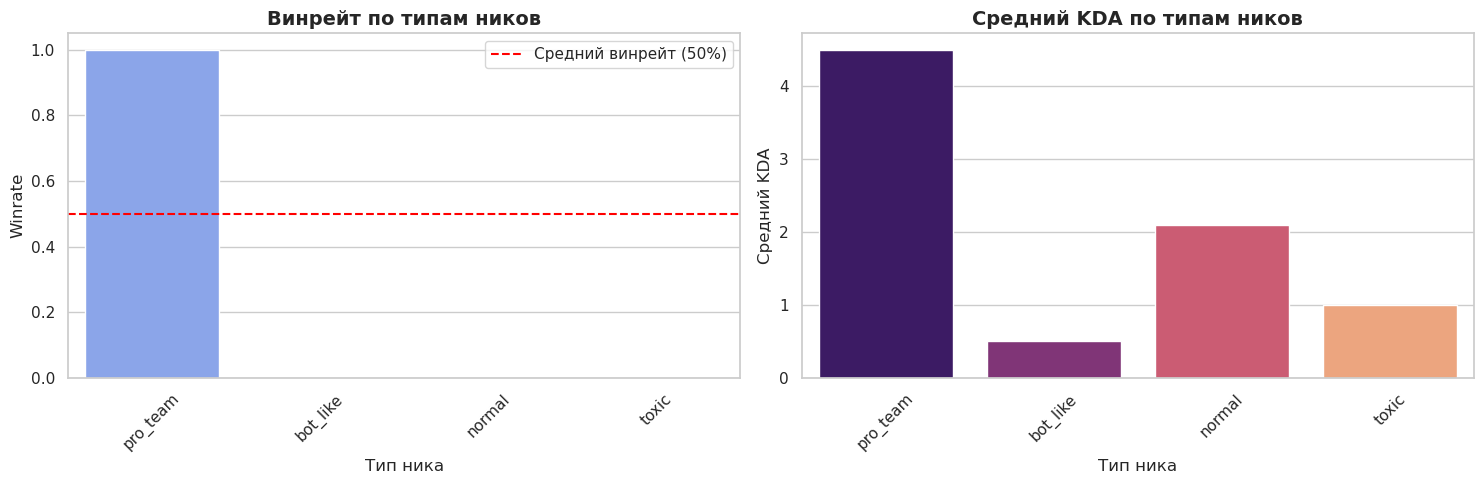

    type  matches  winrate  avg_kda
pro_team     1000      1.0      4.5
bot_like     1000      0.0      0.5
  normal     1000      0.0      2.1
   toxic     1000      0.0      1.0


In [5]:
# Считаем винрейт и средний KDA по типам ников
type_stats = df.groupby('type').agg(
    matches=('account_id', 'count'),
    winrate=('win_num', 'mean'),
    avg_kda=('kda', 'mean')
).reset_index()

# Сортируем по винрейту
type_stats = type_stats.sort_values('winrate', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# График Винрейта
sns.barplot(data=type_stats, x='type', y='winrate', ax=axes[0], palette='coolwarm')
axes[0].axhline(0.5, color='red', linestyle='--', label='Средний винрейт (50%)')
axes[0].set_title('Винрейт по типам ников', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Winrate')
axes[0].set_xlabel('Тип ника')
axes[0].legend()
axes[0].tick_params(axis='x', rotation=45)

# График KDA
sns.barplot(data=type_stats, x='type', y='avg_kda', ax=axes[1], palette='magma')
axes[1].set_title('Средний KDA по типам ников', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Средний KDA')
axes[1].set_xlabel('Тип ника')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print(type_stats.to_string(index=False))